# Part 3 - Scalable processing: Polars, pandas and Spark

BFT65B final report, walkthrough notebook. Every number below is read from `reports/` or recomputed live by the same scripts the README lists. Seed: `config.SEED = 42`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
import polars as pl
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import config as C

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
R = ROOT / "reports"
print("project root:", ROOT, "| python", sys.version.split()[0], "| polars", pl.__version__, "| seed", C.SEED)


def run(script, *args, tail=25):
    """Run one pipeline script exactly as the README does, and show the end of its output."""
    t = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"})
    lines = (t.stdout + t.stderr).strip().splitlines()
    print("\n".join(lines[-tail:]))
    print(f"\n>>> {script} {' '.join(args)} exited with {t.returncode}")
    assert t.returncode == 0, "step failed"


def csv(name, n=None):
    df = pd.read_csv(R / name)
    display(df if n is None else df.head(n))


def fig(name, width=820):
    display(Image(filename=str(R / name), width=width))

project root: D:\Final BigData | python 3.15.2 | polars 2.1.0 | seed 42


**Goal.** The core transformations in Polars, how the engine runs them, a fair benchmark against pandas,
the same steps in PySpark with matching results, and an argument from measurements about when a cluster
is needed. The benchmarks took about an hour in total, so they are not rerun here; the comparison of
results is.

### Engines on the full panel (median wall time, CPU and peak memory)

In [2]:
csv('p3_engines.csv')

,engine,shuffle_partitions,runs,wall_s,min_s,max_s,cpu_s,peak_rss_gb,avail_start_gb,shuffle_gb,spill_gb,x_slower_than_polars_stream,x_cpu,x_memory
0,polars_stream,0,7,1.785,1.498,2.046,11.6,1.878,4.87,NaN,NaN,1.000,1.000,1.000
1,polars_mem,0,7,1.809,1.601,1.934,8.9,1.708,4.88,NaN,NaN,1.013,0.767,0.909
2,polars_noopt,0,7,2.407,2.165,2.685,17.6,2.774,4.95,NaN,NaN,1.348,1.517,1.477
3,pandas_all,0,5,13.639,13.295,15.485,15.4,2.145,3.92,NaN,NaN,7.641,1.328,1.142
4,pandas_cols,0,5,14.526,12.524,15.069,14.3,1.267,3.76,NaN,NaN,8.138,1.233,0.675
5,spark,18,3,77.742,77.331,78.402,393.8,3.113,3.73,1.040,0.021,43.553,33.948,1.658
6,spark,0,3,105.963,102.980,106.913,424.4,3.315,3.72,1.055,0.000,59.363,36.586,1.765


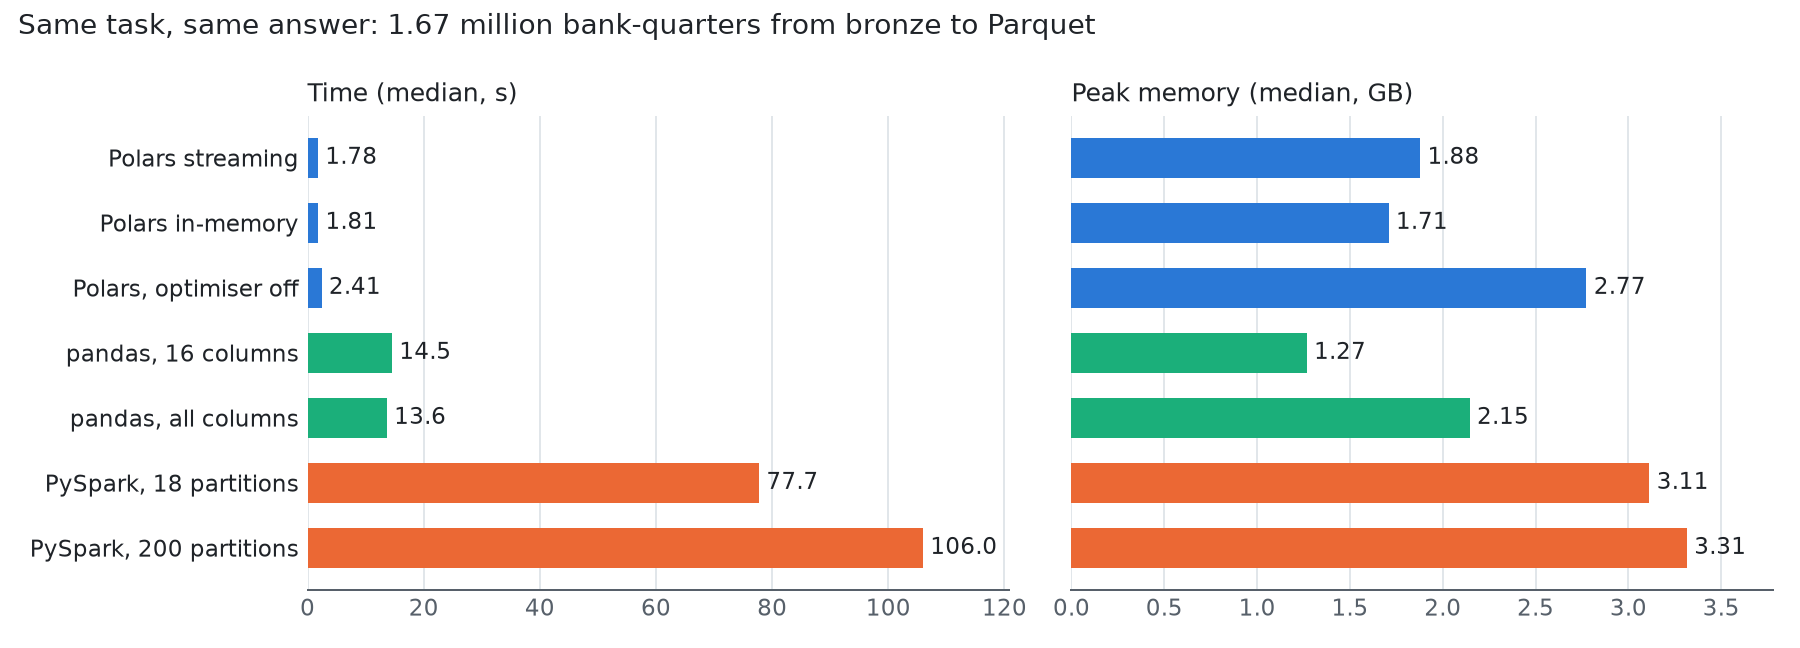

In [3]:
fig('fig_p3_engines.png')

### Do pandas and Spark give the same numbers as Polars? (live)

In [4]:
run('src/p3_compare.py')

shape: (1, 9)
┌────────┬──────────┬───────┬──────────┬────────────┬───────────────┬────────────────┬──────────────┬──────────────┐
│ engine ┆ column   ┆ kind  ┆ rows_ref ┆ rows_other ┆ null_mismatch ┆ value_mismatch ┆ max_abs_diff ┆ max_rel_diff │
│ ---    ┆ ---      ┆ ---   ┆ ---      ┆ ---        ┆ ---           ┆ ---            ┆ ---          ┆ ---          │
│ str    ┆ str      ┆ str   ┆ i64      ┆ i64        ┆ i64           ┆ i64            ┆ f64          ┆ f64          │
╞════════╪══════════╪═══════╪══════════╪════════════╪═══════════════╪════════════════╪══════════════╪══════════════╡
│ pandas ┆ roa_std8 ┆ float ┆ 1666719  ┆ 1666719    ┆ 0             ┆ 5              ┆ 4.0010e-9    ┆ 7.5085e-7    │
└────────┴──────────┴───────┴──────────┴────────────┴───────────────┴────────────────┴──────────────┴──────────────┘
shape: (8, 9)
┌─────────┬──────────┬───────┬──────────┬────────────┬───────────────┬────────────────┬──────────────┬──────────────┐
│ engine  ┆ column   ┆ kind  ┆ rows

In [5]:
print(json.dumps(json.loads((R / 'p3_engine_reconcile.json').read_text()), indent=1)[:1500])

{
 "rows": 1666719,
 "banks": 23788,
 "cells_compared_per_engine": 55001727,
 "y1_rows": 10860,
 "stname_nulls": 0,
 "by_engine": [
  {
   "engine": "Polars streaming",
   "null_mismatch": 0,
   "value_mismatch": 0,
   "max_abs_diff": 0.0,
   "max_rel_diff_exact_cols": 0.0
  },
  {
   "engine": "PySpark",
   "null_mismatch": 0,
   "value_mismatch": 0,
   "max_abs_diff": 5.684341886080802e-14,
   "max_rel_diff_exact_cols": 0.0
  },
  {
   "engine": "pandas",
   "null_mismatch": 0,
   "value_mismatch": 5,
   "max_abs_diff": 4.00096466894595e-09,
   "max_rel_diff_exact_cols": 0.0
  }
 ],
 "against_silver": {
  "silver_rows": 1666719,
  "core_rows": 1666719,
  "rows_only_in_one": 0,
  "cell_differences": {
   "q_idx": 0,
   "ASSET": 0,
   "EQ": 0,
   "RBC1AAJ": 0,
   "LIAB": 0,
   "DEP": 0,
   "CHBAL": 0,
   "LNLSGR": 0,
   "NCLNLS": 0,
   "NETINC_Q": 0,
   "INTINC_Q": 0,
   "EINTEXP_Q": 0,
   "NTLNLS_Q": 0,
   "y": 0,
   "_fail_date": 0
  }
 },
 "pandas_roa_std8_arbitration": [
  {
   "CE

### How Polars executes it: the optimised plan of a small query (live)

In [6]:
lf = (pl.scan_parquet(C.DATA_SILVER / "panel" / "**/*.parquet", hive_partitioning=True)
        .filter(pl.col("REPDTE") >= pl.date(2008, 1, 1))
        .group_by("STNAME").agg(pl.col("ROA").mean()))
print(lf.explain())

AGGREGATE[maintain_order: false]
  [col("ROA").mean()] BY [col("STNAME")]
  FROM
  simple π 2/2 ["STNAME", "ROA"]
    Parquet SCAN [D:/Final BigData/data/silver/panel/YEAR=1984/part-0.parquet, ... 42 other sources]
    PROJECT 3/65 COLUMNS
    SELECTION: col("REPDTE") >= 2008-01-01
    ESTIMATED ROWS: 1687335


In [7]:
print((R / 'p3_plan_polars.txt').read_text(encoding='utf-8')[:3000])

=== CORE PIPELINE: logical plan as written ===
SORT BY [col("CERT"), col("REPDTE")]
  SELECT [col("CERT"), col("REPDTE"), col("YEAR"), col("STNAME"), col("q_idx"), col("ASSET"), col("EQ"), col("RBC1AAJ"), col("LIAB"), col("DEP"), col("CHBAL"), col("LNLSGR"), col("NCLNLS"), col("NETINC_Q"), col("INTINC_Q"), col("EINTEXP_Q"), col("NTLNLS_Q"), col("eq_ta"), col("npl"), col("cash_ta"), col("loan_dep"), col("roa_q"), col("nim_q"), col("nco_q"), col("eq_ta_d4"), col("asset_g4"), col("npl_d1"), col("roa_4q"), col("roa_std8"), col("eq_ta_pct"), col("npl_pct"), col("eq_ta_st_med"), col("eq_ta_gap"), col("y"), col("_fail_date")]
     WITH_COLUMNS:
     [(col("eq_ta") - col("eq_ta_st_med")).alias("eq_ta_gap"), when(col("q_idx") <= 8101).then((((((col("_fail_date").dt.year() * 4) + col("_fail_date").dt.quarter().cast(Int32)) - 1) - col("q_idx"))).is_between([1, 4]).fill_null([false]).strict_cast(Int8)).otherwise(null.cast(Int8)).alias("y")] 
      LEFT JOIN:
      LEFT PLAN ON: [col("REPDTE"), col

### Spark plan summary and stages

In [8]:
print(json.dumps(json.loads((R / 'p3_plan_summary.json').read_text()), indent=1))

{
 "polars_streaming_nodes": {
  "select": 14,
  "with-columns": 9,
  "window": 4,
  "multi-scan": 3,
  "sort": 2,
  "equi-join": 2,
  "multiplexer": 1,
  "filter": 1,
  "semi-join": 1,
  "group-by": 1,
  "in-memory-map": 1
 },
 "polars_rows": 1666719,
 "filter_before_windows_changes": {
  "rows": 33614,
  "cells_changed": {
   "eq_ta_d4": 33053,
   "asset_g4": 33053,
   "roa_4q": 28314,
   "roa_std8": 32374,
   "NETINC_Q": 0,
   "npl_d1": 8380,
   "eq_ta_pct": 0,
   "y": 0
  }
 },
 "spark": {
  "toArrow_s": 95.4,
  "rows": 1666719,
  "final_flag": true,
  "final_plan_nodes": {
   "Exchange": 7,
   "ReusedExchange": 2,
   "Sort": 6,
   "Window": 6,
   "SortMergeJoin": 1,
   "BroadcastHashJoin": 4,
   "HashAggregate": 4,
   "ObjectHashAggregate": 2,
   "AQEShuffleRead": 7
  },
  "parquet_scans_of_financials": 4,
  "stages": 11,
  "shuffle_write_gb": 1.055,
  "shuffle_read_gb": 1.374,
  "spill_mb": 0.0,
  "executor_run_s": 1248.3999999999999,
  "gc_s": 16.200000000000003,
  "selective_pa

In [9]:
csv('p3_spark_stages.csv')

,stage,tasks,input_mb,shuffle_read_mb,shuffle_write_mb,output_records,spill_disk_mb,executor_run_s,jvm_gc_s,name
0,0,43,0.0,0.0,0.0,0,0.0,3.0,0.3,parquet at DirectMethodHandleAccessor.java:103
1,1,1,0.0,0.0,0.0,0,0.0,0.7,0.0,parquet at DirectMethodHandleAccessor.java:103
2,2,1,0.0,0.0,0.0,0,0.0,0.0,0.0,parquet at DirectMethodHandleAccessor.java:103
3,3,1,0.0,0.0,0.0,0,0.0,0.0,0.0,parquet at DirectMethodHandleAccessor.java:103
4,4,1,0.0,0.0,0.3,0,0.0,4.4,0.0,toArrow at D:\Final BigData\src\p3_plans.py:135
5,5,1,0.0,0.0,0.0,0,0.0,4.3,0.0,toArrow at D:\Final BigData\src\p3_plans.py:135
6,7,1,0.0,0.0,0.0,0,0.0,0.2,0.0,toArrow at D:\Final BigData\src\p3_plans.py:135
7,9,1,0.0,0.3,0.0,0,0.0,0.2,0.0,toArrow at D:\Final BigData\src\p3_plans.py:135
8,10,19,3.0,0.0,17.4,0,0.0,241.3,5.4,toArrow at D:\Final BigData\src\p3_plans.py:135
9,11,19,3.0,0.0,122.6,0,0.0,136.5,0.7,toArrow at D:\Final BigData\src\p3_plans.py:135


### Threads and data scale: where a laptop stops

In [10]:
csv('p3_threads.csv'); csv('p3_scale.csv')

,engine,threads,runs,wall_s,min_s,max_s,cpu_s,peak_rss_gb,avail_start_gb,shuffle_gb,spill_gb,speedup,efficiency
0,polars_mem,1,3,5.239,5.173,5.330,5.10,0.990,4.770,NaN,NaN,1.000,1.000
1,polars_mem,2,3,2.832,2.832,2.887,5.00,1.080,4.690,NaN,NaN,1.850,0.925
2,polars_mem,4,3,1.986,1.984,2.228,5.40,1.091,4.880,NaN,NaN,2.638,0.659
3,polars_mem,8,3,1.696,1.635,1.756,7.40,1.300,4.890,NaN,NaN,3.089,0.386
4,polars_mem,12,3,1.548,1.545,1.590,7.70,1.372,4.700,NaN,NaN,3.384,0.282
5,polars_mem,18,3,1.645,1.588,1.714,8.80,1.757,4.710,NaN,NaN,3.185,0.177
6,polars_stream,1,3,6.541,6.388,6.627,6.30,1.107,4.900,NaN,NaN,1.000,1.000
7,polars_stream,2,3,3.398,3.282,3.406,6.00,1.209,4.700,NaN,NaN,1.925,0.962
8,polars_stream,4,3,2.210,2.162,2.253,7.20,1.585,4.880,NaN,NaN,2.960,0.740
9,polars_stream,8,3,1.623,1.622,1.653,9.40,1.780,4.820,NaN,NaN,4.030,0.504


,spec,scale,status,wall_s,cpu_s,peak_rss_gb,avail_start_gb,heap,shuffle_partitions,shuffle_gb,spill_gb,retries,rows,m_rows_per_s
0,pandas_cols,1,ok,14.526,14.3,1.267,3.76,NaN,NaN,NaN,NaN,NaN,1666719,0.115
1,pandas_cols,2,ok,27.850,28.1,2.334,3.89,NaN,0.0,NaN,NaN,0.0,3333438,0.120
2,pandas_cols,4,memory_guard,5.284,8.0,3.041,3.34,NaN,0.0,NaN,NaN,0.0,6666876,NaN
3,polars_mem,1,ok,1.809,8.9,1.708,4.88,NaN,NaN,NaN,NaN,NaN,1666719,0.921
4,polars_mem,2,ok,4.225,27.2,2.905,3.66,NaN,0.0,NaN,NaN,0.0,3333438,0.789
5,polars_mem,4,memory_guard,6.110,27.3,3.459,3.88,NaN,0.0,NaN,NaN,0.0,6666876,NaN
6,polars_mem@4,1,ok,1.986,5.4,1.091,4.88,NaN,NaN,NaN,NaN,NaN,1666719,0.839
7,polars_mem@4,2,ok,5.071,15.0,1.954,3.61,NaN,0.0,NaN,NaN,0.0,3333438,0.657
8,polars_mem@4,4,memory_guard,6.096,15.0,3.574,3.62,NaN,0.0,NaN,NaN,1.0,6666876,NaN
9,polars_stream,1,ok,1.785,11.6,1.878,4.87,NaN,NaN,NaN,NaN,NaN,1666719,0.934


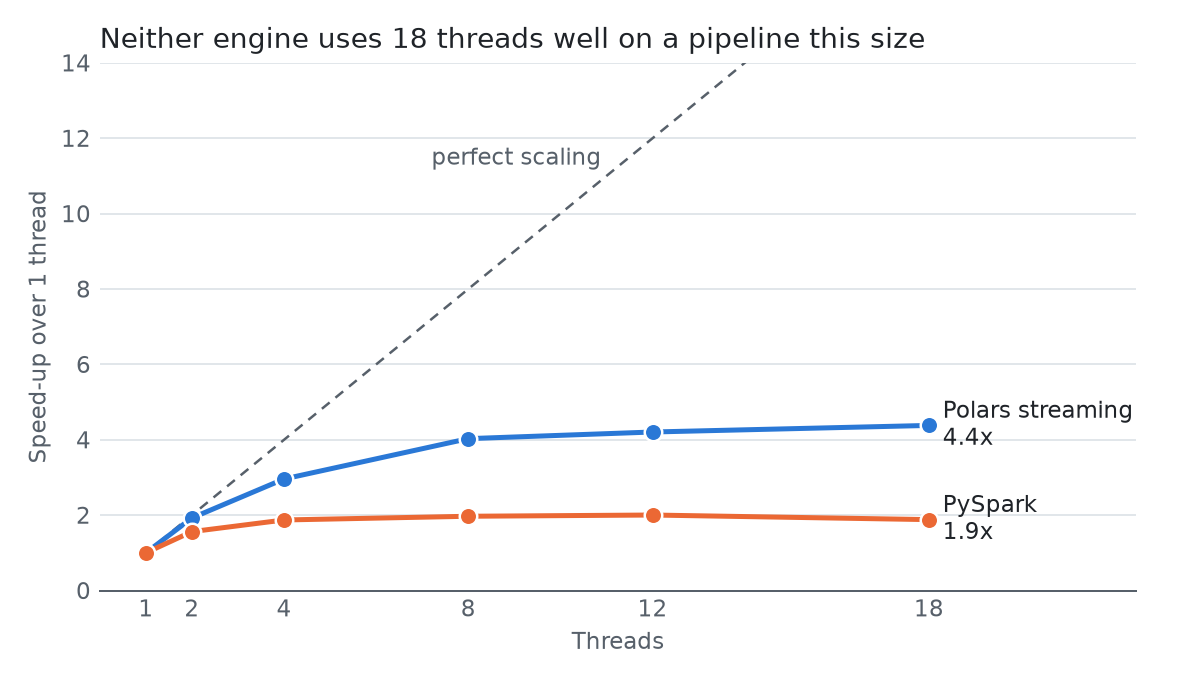

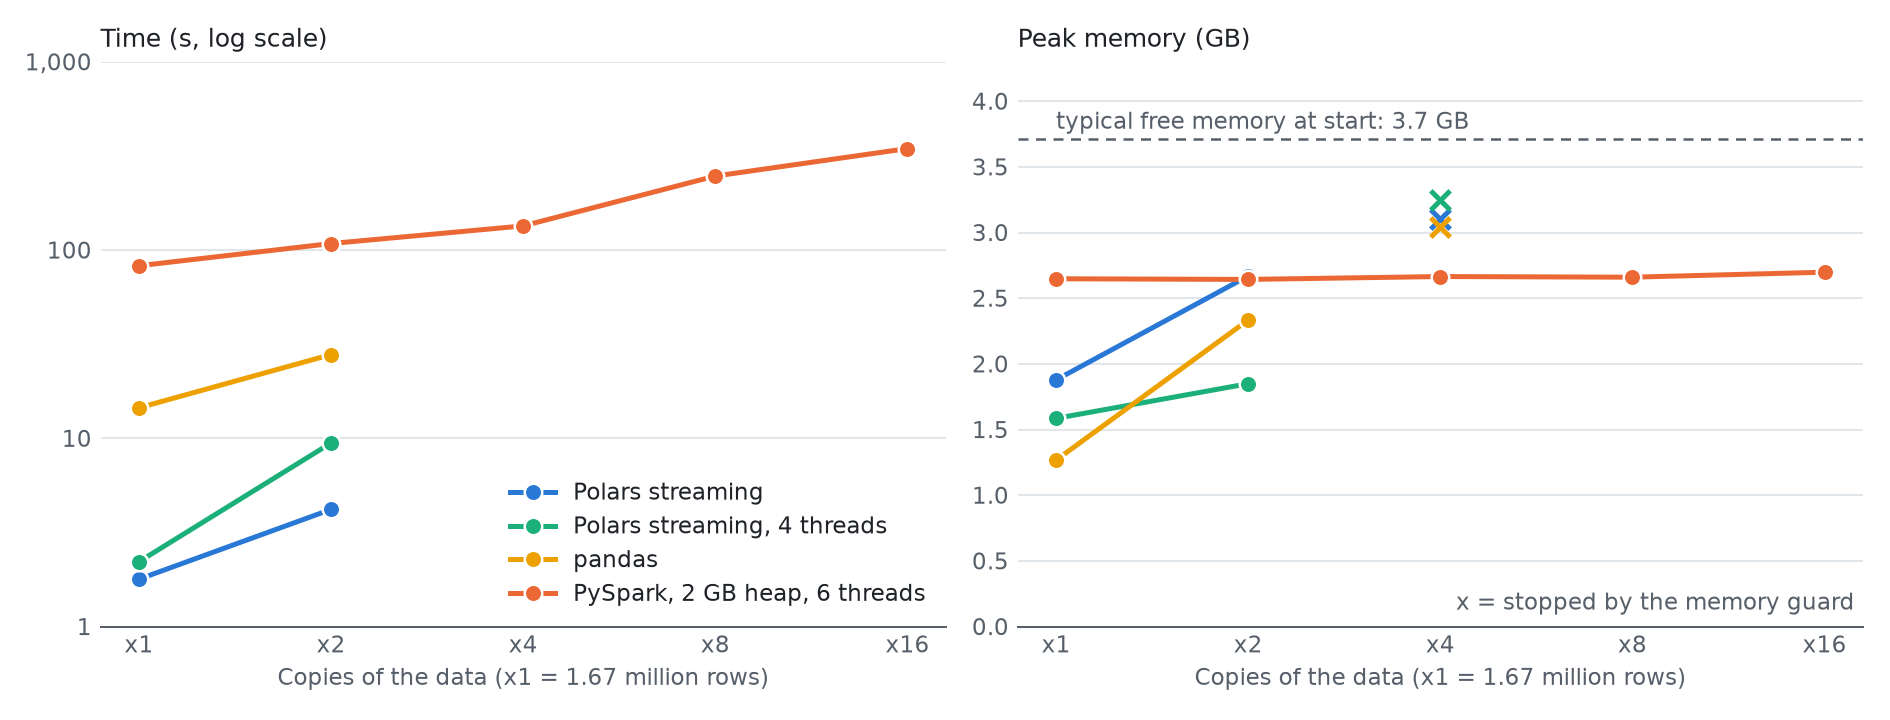

In [11]:
fig('fig_p3_threads.png'); fig('fig_p3_scale.png')

In [12]:
print(json.dumps(json.loads((R / 'p3_cluster_case.json').read_text()), indent=1))

{
 "data": {
  "rows_panel": 1666719,
  "rows_added_in_2025": 17612,
  "years_of_growth_to_double": 94.6
 },
 "polars_streaming": {
  "wall_s": 1.785,
  "cpu_s": 11.6,
  "peak_gb": 1.878
 },
 "spark_default": {
  "wall_s": 105.963,
  "cpu_s": 424.4,
  "peak_gb": 3.315
 },
 "spark_best_setting": {
  "threads": 0,
  "shuffle_partitions": 18,
  "heap": "3g",
  "wall_s": 56.775,
  "cpu_s": 317.5,
  "peak_rss_gb": 3.258
 },
 "cpu_ratio_spark_to_polars": 27.4,
 "cpu_ratio_spark_to_polars_1_thread": 29.0,
 "cores_spark_needs_to_match_polars_at_perfect_scaling": 84,
 "speedup": {
  "polars_stream_best": {
   "threads": 18,
   "speedup": 4.38
  },
  "spark_best": {
   "threads": 12,
   "speedup": 2.0
  },
  "spark_at_18": 1.88
 },
 "network_lower_bound": {
  "assumption": "10 Gb/s link, 1.25 GB/s, every shuffled byte crosses it once, no contention. Assumed, not measured.",
  "shuffle_gb_per_run_x1": 1.055,
  "seconds_x1": 0.84
 },
 "memory_extrapolation_not_measured": {
  "polars_stream": {
   